PATHSNAP XGBOOST TRAINING
Training trips: 80
Student testing trips: 10

Generating candidate features...
Feature generation completed!

Loading 80 training trips...
00000001: 1315 GPS points, 44763 candidates, 1315 positive labels
00000002: 7243 GPS points, 226672 candidates, 6524 positive labels
00000003: 821 GPS points, 61416 candidates, 821 positive labels
00000004: 1064 GPS points, 14854 candidates, 1064 positive labels
00000005: 1045 GPS points, 4918 candidates, 1045 positive labels
00000006: 1450 GPS points, 35787 candidates, 1450 positive labels
00000008: 3093 GPS points, 101248 candidates, 3093 positive labels
00000010: 2711 GPS points, 133848 candidates, 2711 positive labels
00000011: 2828 GPS points, 36169 candidates, 2828 positive labels
00000012: 1608 GPS points, 11524 candidates, 1608 positive labels
00000013: 2580 GPS points, 63518 candidates, 2580 positive labels
00000014: 448 GPS points, 22528 candidates, 448 positive labels
00000016: 1305 GPS points, 61136 candidates, 

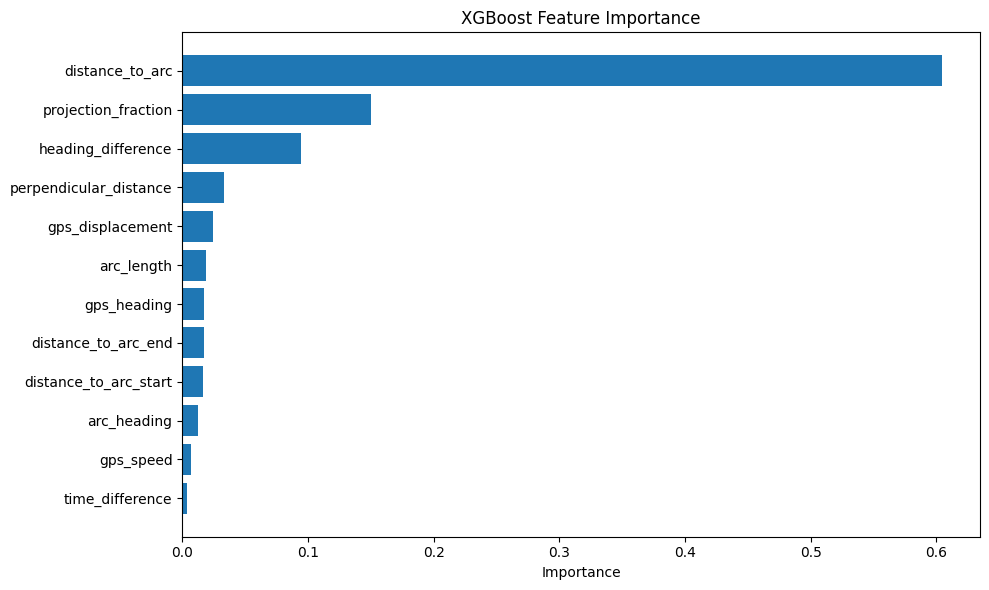

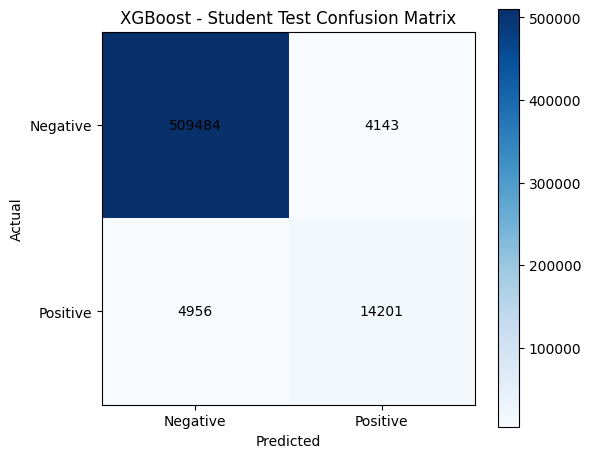


Results copied to Google Drive!

XGBOOST EXPERIMENT COMPLETED
Total execution time: 4124.47 seconds
Saved model: /content/PathSnap_XGBoost_Results/xgb_model.json
Saved metrics: /content/PathSnap_XGBoost_Results/xgb_results.csv
Saved predictions: /content/PathSnap_XGBoost_Results/student_predictions.csv


In [45]:

# ============================================================
# PATHSNAP HACKATHON - COMPLETE XGBOOST EXPERIMENT
# Candidate classification + route-oriented evaluation
# ============================================================

!pip -q install xgboost scikit-learn scipy pandas numpy matplotlib seaborn

import os
import glob
import json
import time
import shutil
import subprocess
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path
from scipy.spatial import cKDTree
from xgboost import XGBClassifier

from sklearn.model_selection import GroupShuffleSplit
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, confusion_matrix, log_loss,
    classification_report
)

warnings.filterwarnings("ignore")

START_TIME = time.time()
RADIUS = 100.0
SEED = 42

FEATURES = [
    "distance_to_arc",
    "perpendicular_distance",
    "distance_to_arc_start",
    "distance_to_arc_end",
    "projection_fraction",
    "arc_length",
    "arc_heading",
    "gps_heading",
    "heading_difference",
    "gps_speed",
    "gps_displacement",
    "time_difference"
]

print("=" * 60)
print("PATHSNAP XGBOOST TRAINING")
print("=" * 60)

# ------------------------------------------------------------
# 1. FIND DATASET
# ------------------------------------------------------------

TRAIN_DIR = Path("/content/Datasets/train")
TEST_DIR = Path("/content/Datasets/student_test")

# Handle nested extraction if necessary
if not TRAIN_DIR.exists():
    nested = Path("/content/Datasets/Student folder")

    if (nested / "train").exists():
        shutil.move(str(nested / "train"), str(TRAIN_DIR))
        shutil.move(str(nested / "student_test"), str(TEST_DIR))

assert TRAIN_DIR.exists(), "Training folder not found!"
assert TEST_DIR.exists(), "Student testing folder not found!"

SCRIPT = Path("/content/enrich_features.py")

if not SCRIPT.exists():
    SCRIPT = Path(
        "/content/drive/MyDrive/Colab Notebooks/enrich_features.py"
    )

assert SCRIPT.exists(), "enrich_features.py not found!"

print("Training trips:", len(list(TRAIN_DIR.iterdir())))
print("Student testing trips:", len(list(TEST_DIR.iterdir())))

# ------------------------------------------------------------
# 2. GENERATE CANDIDATE FEATURES
# ------------------------------------------------------------

print("\nGenerating candidate features...")

subprocess.run(
    ["python", str(SCRIPT), "--all", "--radius", str(RADIUS)],
    cwd="/content",
    check=True
)

print("Feature generation completed!")

# ------------------------------------------------------------
# 3. CREATE APPROXIMATE TRAINING LABELS
# ------------------------------------------------------------

EARTH_RADIUS = 6371000.0

def project(lon, lat, lon0, lat0):
    x = np.radians(lon - lon0) * EARTH_RADIUS * np.cos(
        np.radians(lat0)
    )
    y = np.radians(lat - lat0) * EARTH_RADIUS
    return np.column_stack((x, y))


def get_reference_labels(trip_dir):
    """
    Associate each GPS observation with its nearest
    reference-route arc using projected geometry.

    This is an approximate observation-to-route alignment,
    not independently verified ground truth.
    """

    trip_dir = Path(trip_dir)
    trip = trip_dir.name

    track = np.loadtxt(
        trip_dir / f"{trip}.track", ndmin=2
    )

    nodes = np.loadtxt(
        trip_dir / f"{trip}.nodes", ndmin=2
    )

    arcs = np.loadtxt(
        trip_dir / f"{trip}.arcs",
        dtype=int, ndmin=2
    )

    route = np.loadtxt(
        trip_dir / f"{trip}.route",
        dtype=int, ndmin=1
    )

    route = np.unique(route.astype(int))

    if len(route) == 0:
        raise ValueError("Empty reference route")

    if np.any(route < 0) or np.any(route >= len(arcs)):
        raise ValueError("Invalid reference arc ID")

    lon0 = np.mean(nodes[:, 0])
    lat0 = np.mean(nodes[:, 1])

    nodes_xy = project(
        nodes[:, 0], nodes[:, 1], lon0, lat0
    )

    gps_xy = project(
        track[:, 0], track[:, 1], lon0, lat0
    )

    starts = nodes_xy[arcs[route, 0]]
    ends = nodes_xy[arcs[route, 1]]

    vectors = ends - starts
    lengths_sq = np.sum(vectors ** 2, axis=1)

    midpoints = (starts + ends) / 2

    tree = cKDTree(midpoints)

    k = min(50, len(route))

    distances, indices = tree.query(gps_xy, k=k)

    if k == 1:
        indices = indices.reshape(-1, 1)

    labels = {}

    for gps_id, point in enumerate(gps_xy):

        candidate_indices = np.asarray(indices[gps_id]).reshape(-1)

        candidate_starts = starts[candidate_indices]
        candidate_vectors = vectors[candidate_indices]
        candidate_lengths = lengths_sq[candidate_indices]

        offsets = point - candidate_starts

        fractions = np.zeros(len(candidate_indices))

        valid = candidate_lengths > 1e-12

        fractions[valid] = (
            np.sum(
                offsets[valid] * candidate_vectors[valid],
                axis=1
            ) / candidate_lengths[valid]
        )

        fractions = np.clip(fractions, 0, 1)

        projections = (
            candidate_starts +
            fractions[:, None] * candidate_vectors
        )

        exact_distances = np.linalg.norm(
            point - projections, axis=1
        )

        best = np.argmin(exact_distances)

        best_arc = int(route[candidate_indices[best]])

        labels[gps_id] = best_arc

    return labels, len(track), arcs


# ------------------------------------------------------------
# 4. LOAD FEATURE CSVs AND ASSIGN LABELS
# ------------------------------------------------------------

def load_partition(partition_dir):

    frames = []
    reference_maps = {}
    observation_counts = {}
    arc_maps = {}

    trip_dirs = sorted([
        p for p in partition_dir.iterdir()
        if p.is_dir()
    ])

    for trip_dir in trip_dirs:

        trip = trip_dir.name

        csv_path = trip_dir / f"{trip}.enrich.csv"

        if not csv_path.exists():
            print("[SKIP] Missing:", csv_path)
            continue

        try:

            reference, count, arcs = get_reference_labels(
                trip_dir
            )

            df = pd.read_csv(csv_path)

            if df.empty:
                continue

            df["trip_id"] = trip

            df["label"] = df.apply(
                lambda row: int(
                    reference.get(int(row["gps_id"]), -999)
                    == int(row["arc_id"])
                ),
                axis=1
            )

            # Remove candidates for observations without
            # a valid reference label.
            df = df[df["label"] >= 0].copy()

            frames.append(df)

            reference_maps[trip] = reference
            observation_counts[trip] = count
            arc_maps[trip] = arcs

            print(
                f"{trip}: {count} GPS points, "
                f"{len(df)} candidates, "
                f"{df['label'].sum()} positive labels"
            )

        except Exception as e:
            print("[ERROR]", trip, str(e))

    if not frames:
        raise RuntimeError("No usable feature data found!")

    return (
        pd.concat(frames, ignore_index=True),
        reference_maps,
        observation_counts,
        arc_maps
    )


print("\nLoading 80 training trips...")

train_df, train_refs, train_counts, train_arcs = (
    load_partition(TRAIN_DIR)
)

print("\nLoading 10 student testing trips...")

test_df, test_refs, test_counts, test_arcs = (
    load_partition(TEST_DIR)
)

print("\nTraining candidate rows:", len(train_df))
print("Testing candidate rows:", len(test_df))

print("\nLabel distribution:")
print(train_df["label"].value_counts())

if train_df["label"].nunique() < 2:
    raise RuntimeError(
        "Training labels contain only one class. "
        "Inspect route-to-GPS label alignment."
    )

# ------------------------------------------------------------
# 5. PREPARE TRAINING DATA
# ------------------------------------------------------------

X = train_df[FEATURES].replace(
    [np.inf, -np.inf], np.nan
)

y = train_df["label"].astype(int)

groups = train_df["trip_id"]

X_test = test_df[FEATURES].replace(
    [np.inf, -np.inf], np.nan
)

y_test = test_df["label"].astype(int)

# Split by trip, never by random candidate row
splitter = GroupShuffleSplit(
    n_splits=1,
    test_size=0.20,
    random_state=SEED
)

train_idx, val_idx = next(
    splitter.split(X, y, groups)
)

X_train = X.iloc[train_idx]
X_val = X.iloc[val_idx]

y_train = y.iloc[train_idx]
y_val = y.iloc[val_idx]

val_df = train_df.iloc[val_idx].copy()

print("\nTraining trips:",
      groups.iloc[train_idx].nunique())

print("Validation trips:",
      groups.iloc[val_idx].nunique())

# ------------------------------------------------------------
# 6. TRAIN XGBOOST
# ------------------------------------------------------------

model = XGBClassifier(
    n_estimators=400,
    max_depth=6,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    min_child_weight=3,
    reg_lambda=2,
    objective="binary:logistic",
    eval_metric="logloss",
    tree_method="hist",
    random_state=SEED,
    n_jobs=-1
)

print("\nTraining XGBoost...")

training_start = time.perf_counter()

model.fit(X_train, y_train)

training_time = time.perf_counter() - training_start

print("Training completed!")
print("Training time:", round(training_time, 3), "seconds")

# ------------------------------------------------------------
# 7. EVALUATION FUNCTIONS
# ------------------------------------------------------------

def calculate_metrics(df, probabilities, y_true):

    predictions = (probabilities >= 0.5).astype(int)

    print("\nCandidate-level metrics")

    print("Accuracy:",
          accuracy_score(y_true, predictions))

    print("Precision:",
          precision_score(
              y_true, predictions, zero_division=0
          ))

    print("Recall:",
          recall_score(
              y_true, predictions, zero_division=0
          ))

    print("F1 Score:",
          f1_score(
              y_true, predictions, zero_division=0
          ))

    print("Log Loss:",
          log_loss(
              y_true, probabilities, labels=[0, 1]
          ))

    cm = confusion_matrix(
        y_true, predictions, labels=[0, 1]
    )

    print("\nConfusion Matrix:")
    print(cm)

    print("\nClassification Report:")
    print(classification_report(
        y_true, predictions, zero_division=0
    ))

    return cm


def route_metrics(
    df, probabilities, refs, counts, arc_maps
):

    temp = df[
        ["trip_id", "gps_id", "arc_id"]
    ].copy()

    temp["probability"] = probabilities

    # Select highest probability candidate per observation
    best = temp.loc[
        temp.groupby(
            ["trip_id", "gps_id"]
        )["probability"].idxmax()
    ]

    predictions = {}

    for _, row in best.iterrows():
        predictions.setdefault(
            row["trip_id"], {}
        )[int(row["gps_id"])] = int(row["arc_id"])

    all_correct = []
    misses = []
    continuity_values = []

    for trip, reference in refs.items():

        total = counts[trip]
        pred = predictions.get(trip, {})

        trip_correct = []

        for gps_id in range(total):

            ref_arc = reference[gps_id]

            if gps_id not in pred:
                misses.append(1)
                trip_correct.append(False)
                continue

            misses.append(0)

            correct = pred[gps_id] == ref_arc

            trip_correct.append(correct)

        all_correct.extend(trip_correct)

        # Directed road connectivity:
        # same arc OR previous arc's end node equals
        # next arc's start node.
        arcs = arc_maps[trip]

        trip_pred = sorted(pred.items())

        connected = []
        for i in range(1, len(trip_pred)):

            previous_arc = trip_pred[i - 1][1]
            current_arc = trip_pred[i][1]

            if (
                previous_arc == current_arc
                or arcs[previous_arc, 1]
                == arcs[current_arc, 0]
            ):
                connected.append(1)
            else:
                connected.append(0)

        if connected:
            continuity_values.append(np.mean(connected))

    top1 = np.mean(all_correct) if all_correct else 0

    miss_rate = np.mean(misses) if misses else 0

    continuity = (
        np.mean(continuity_values)
        if continuity_values else 0
    )

    # Exact-trip accuracy against approximate point labels
    sequence_exact = np.mean([
        all(
            pred.get(gps_id) == reference[gps_id]
            for gps_id in range(counts[trip])
        )
        for trip, reference in refs.items()
        for pred in [predictions.get(trip, {})]
    ])

    print("\nRoute-oriented metrics")

    print("Observation-level Top-1 Accuracy:",
          round(top1, 5))

    print("Candidate Miss Rate:",
          round(miss_rate, 5))

    print("Route Continuity:",
          round(continuity, 5))

    print("Sequence-level Exact Accuracy:",
          round(sequence_exact, 5))

    return {
        "top1_accuracy": top1,
        "candidate_miss_rate": miss_rate,
        "route_continuity": continuity,
        "sequence_exact_accuracy": sequence_exact
    }


# ------------------------------------------------------------
# 8. VALIDATION EVALUATION
# ------------------------------------------------------------

print("\n" + "=" * 60)
print("VALIDATION RESULTS - HELD-OUT TRAINING TRIPS")
print("=" * 60)

inference_start = time.perf_counter()

val_prob = model.predict_proba(X_val)[:, 1]

validation_inference_time = (
    time.perf_counter() - inference_start
)

val_cm = calculate_metrics(
    val_df, val_prob, y_val
)

# Validation reference dictionaries only
val_trip_ids = set(val_df["trip_id"])

val_refs = {
    k: v for k, v in train_refs.items()
    if k in val_trip_ids
}

val_counts = {
    k: v for k, v in train_counts.items()
    if k in val_trip_ids
}

val_arcs = {
    k: v for k, v in train_arcs.items()
    if k in val_trip_ids
}

val_route_results = route_metrics(
    val_df, val_prob,
    val_refs, val_counts, val_arcs
)

print("Validation inference time:",
      round(validation_inference_time, 4), "seconds")

# ------------------------------------------------------------
# 9. REFIT ON ALL 80 TRAINING TRIPS
# ------------------------------------------------------------

print("\nRefitting XGBoost on all training trips...")

final_model = XGBClassifier(
    n_estimators=400,
    max_depth=6,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    min_child_weight=3,
    reg_lambda=2,
    objective="binary:logistic",
    eval_metric="logloss",
    tree_method="hist",
    random_state=SEED,
    n_jobs=-1
)

final_start = time.perf_counter()

final_model.fit(X, y)

final_training_time = time.perf_counter() - final_start

# ------------------------------------------------------------
# 10. STUDENT TEST EVALUATION
# ------------------------------------------------------------

print("\n" + "=" * 60)
print("STUDENT TEST RESULTS - 10 HELD-OUT TRIPS")
print("=" * 60)

inference_start = time.perf_counter()

test_prob = final_model.predict_proba(X_test)[:, 1]

student_inference_time = (
    time.perf_counter() - inference_start
)

test_cm = calculate_metrics(
    test_df, test_prob, y_test
)

test_route_results = route_metrics(
    test_df, test_prob,
    test_refs, test_counts, test_arcs
)

print("Student test inference time:",
      round(student_inference_time, 4), "seconds")

print("Average time per candidate:",
      round(
          student_inference_time / max(len(X_test), 1),
          8
      ), "seconds")

# ------------------------------------------------------------
# 11. FEATURE IMPORTANCE
# ------------------------------------------------------------

importance = pd.DataFrame({
    "Feature": FEATURES,
    "Importance": final_model.feature_importances_
}).sort_values(
    "Importance", ascending=False
)

print("\nFeature Importance:")
print(importance.to_string(index=False))

plt.figure(figsize=(10, 6))

plt.barh(
    importance["Feature"],
    importance["Importance"]
)

plt.gca().invert_yaxis()
plt.title("XGBoost Feature Importance")
plt.xlabel("Importance")
plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 12. CONFUSION MATRIX VISUALIZATION
# ------------------------------------------------------------

plt.figure(figsize=(6, 5))

plt.imshow(test_cm, cmap="Blues")

plt.title("XGBoost - Student Test Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")

plt.xticks([0, 1], ["Negative", "Positive"])
plt.yticks([0, 1], ["Negative", "Positive"])

for i in range(2):
    for j in range(2):
        plt.text(
            j, i, test_cm[i, j],
            ha="center", va="center"
        )

plt.colorbar()
plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 13. SAVE MODEL AND RESULTS
# ------------------------------------------------------------

OUTPUT = "/content/PathSnap_XGBoost_Results"

os.makedirs(OUTPUT, exist_ok=True)

final_model.save_model(
    OUTPUT + "/xgb_model.json"
)

importance.to_csv(
    OUTPUT + "/feature_importance.csv",
    index=False
)

results = {
    "model": "XGBoost",
    "parameters": final_model.get_params(),
    "validation_training_time_seconds": training_time,
    "final_training_time_seconds": final_training_time,
    "validation_inference_time_seconds": validation_inference_time,
    "student_inference_time_seconds": student_inference_time,
    "student_candidate_accuracy": float(
        accuracy_score(
            y_test,
            (test_prob >= 0.5).astype(int)
        )
    ),
    "student_precision": float(
        precision_score(
            y_test,
            (test_prob >= 0.5).astype(int),
            zero_division=0
        )
    ),
    "student_recall": float(
        recall_score(
            y_test,
            (test_prob >= 0.5).astype(int),
            zero_division=0
        )
    ),
    "student_f1": float(
        f1_score(
            y_test,
            (test_prob >= 0.5).astype(int),
            zero_division=0
        )
    ),
    "student_log_loss": float(
        log_loss(y_test, test_prob, labels=[0, 1])
    ),
    **{
        "student_" + k: float(v)
        for k, v in test_route_results.items()
    }
}

with open(
    OUTPUT + "/xgb_results.json", "w"
) as f:
    json.dump(results, f, indent=4, default=str)

pd.DataFrame([results]).to_csv(
    OUTPUT + "/xgb_results.csv",
    index=False
)

# Save student predictions for later analysis
predictions = test_df[
    ["trip_id", "gps_id", "arc_id", "label"]
].copy()

predictions["probability"] = test_prob

predictions.to_csv(
    OUTPUT + "/student_predictions.csv",
    index=False
)

# Copy output to Google Drive
DRIVE_OUTPUT = (
    "/content/drive/MyDrive/Colab Notebooks/"
    "PathSnap_XGBoost_Results"
)

try:
    if os.path.exists(DRIVE_OUTPUT):
        shutil.rmtree(DRIVE_OUTPUT)

    shutil.copytree(OUTPUT, DRIVE_OUTPUT)

    print("\nResults copied to Google Drive!")

except Exception as e:
    print("Drive copy skipped:", e)

print("\n" + "=" * 60)
print("XGBOOST EXPERIMENT COMPLETED")
print("=" * 60)

print("Total execution time:",
      round(time.time() - START_TIME, 2), "seconds")

print("Saved model:", OUTPUT + "/xgb_model.json")
print("Saved metrics:", OUTPUT + "/xgb_results.csv")
print("Saved predictions:", OUTPUT + "/student_predictions.csv")
